# Setup

In [1]:
import os
import json 
import numpy as np
from util import *
import matplotlib.pyplot as plt
%matplotlib ipympl

In [2]:
# load preprocessed keypoints
recording_name = 'p2'
keypoints_path = os.path.join('data', recording_name, recording_name+'_keypoints_3d_global.npy')
if not os.path.exists(keypoints_path):
    raise FileNotFoundError(f'File {keypoints_path} does not exist')
keypoints = np.load(keypoints_path)
print(f'loaded: {keypoints_path} \nshape: {keypoints.shape}')

loaded: data\p2\p2_keypoints_3d_global.npy 
shape: (3566, 26, 3)


# Draw trajectories

(3266,)

In [65]:
horizontal.shape

(3266,)

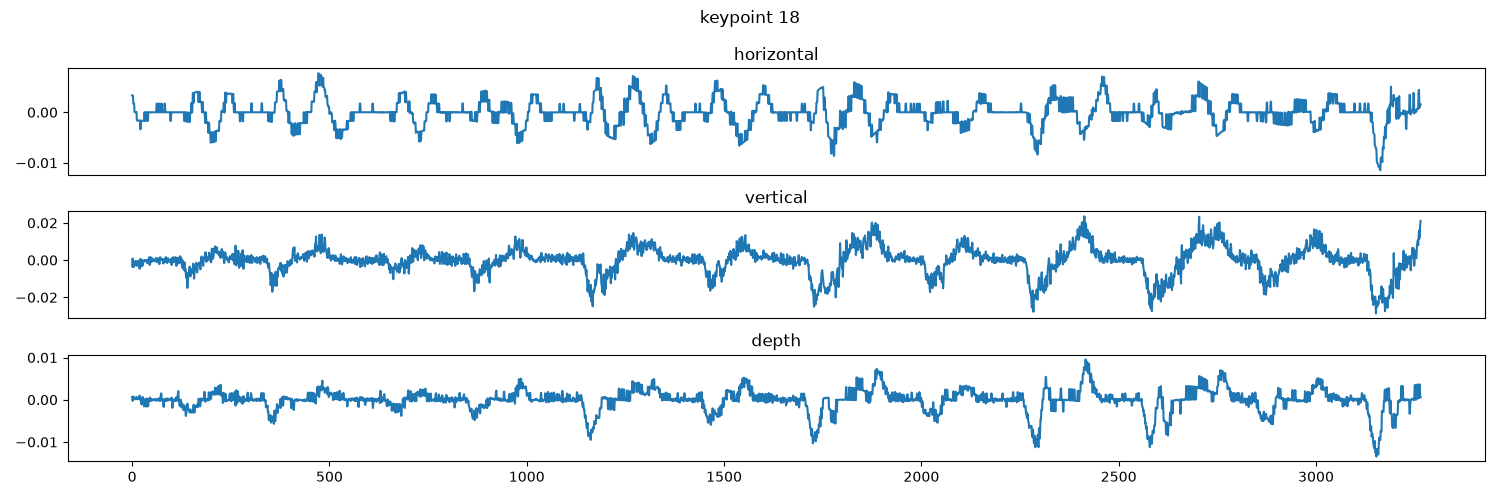

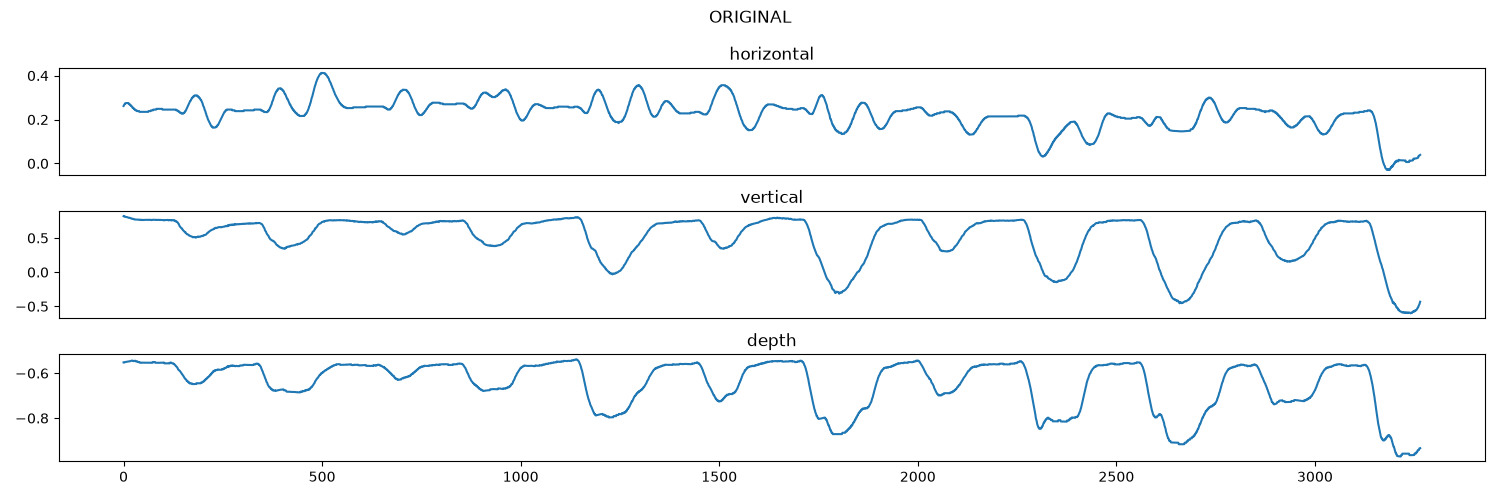

In [4]:
KPT_IDX = 18
cut = 300
PLOT_ORIGINAL = True

horizontal = keypoints[cut:,KPT_IDX,0]
vertical = keypoints[cut:,KPT_IDX,1]
depth = keypoints[cut:,KPT_IDX,2]

# horizontal_acceleration = np.diff(horizontal, n=1, prepend=horizontal[:2])
# vertical_acceleration = np.diff(vertical, n=1, prepend=vertical[:2])
# depth_acceleration = np.diff(depth, n=1, prepend=depth[:2])

# horizontal_acceleration = np.gradient(np.gradient(horizontal))
# vertical_acceleration = np.gradient(np.gradient(vertical))
# depth_acceleration = np.gradient(np.gradient(depth))
horizontal_acceleration = np.gradient(horizontal)
vertical_acceleration = np.gradient(vertical)
depth_acceleration = np.gradient(depth)



plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
fig.suptitle(f'keypoint {KPT_IDX}')

axs[0].set_title('horizontal')
axs[0].plot(horizontal_acceleration)

axs[1].set_title('vertical')
axs[1].plot(vertical_acceleration)

axs[2].set_title('depth')
axs[2].plot(depth_acceleration)
# axs[2].hlines(y=[depth_std+np.nanmean(depth), np.nanmean(depth)-depth_std], xmin=0, xmax=len(depth), color='r')


for ax in axs[:-1]:
    ax.set_xticks([])
    # ax.grid()
plt.tight_layout()


if PLOT_ORIGINAL:
    fig, axs = plt.subplots(3,1, figsize=(15,5))
    fig.suptitle(f'ORIGINAL')

    axs[0].set_title('horizontal')
    axs[0].plot(horizontal)

    axs[1].set_title('vertical')
    axs[1].plot(vertical)

    axs[2].set_title('depth')
    axs[2].plot(depth)


    for ax in axs[:-1]:
        ax.set_xticks([])
        # ax.grid()
    plt.tight_layout()